# Advanced Network Dynamics
In this notebook, we explore network oscillations and synchronous firing in populations of neurons.

## 1. Setup and Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

## 2. Simulating Population Activity
We can simulate the aggregate firing rate of an excitatory and inhibitory population (Wilson-Cowan model).

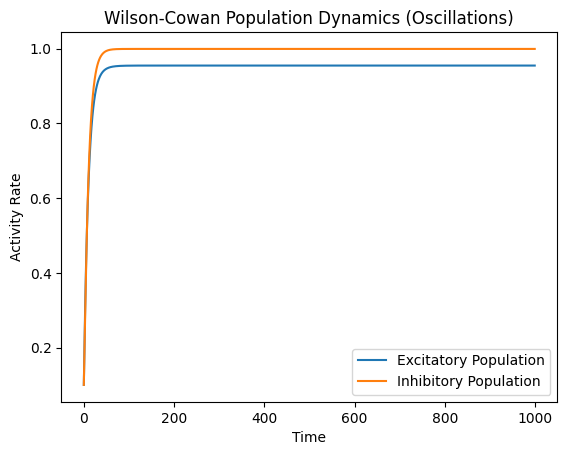

In [2]:
def wilson_cowan(E, I, w_EE, w_EI, w_IE, w_II, I_E, I_I, tau_E=10, tau_I=10):
    def sigmoid(x):
        return 1 / (1 + np.exp(-x))
    
    dE = (-E + sigmoid(w_EE * E - w_EI * I + I_E)) / tau_E
    dI = (-I + sigmoid(w_IE * E - w_II * I + I_I)) / tau_I
    return dE, dI

time_steps = 1000
dt = 1.0
E_pop = np.zeros(time_steps)
I_pop = np.zeros(time_steps)

E_pop[0] = 0.1
I_pop[0] = 0.1

for t in range(1, time_steps):
    dE, dI = wilson_cowan(E_pop[t-1], I_pop[t-1], w_EE=10, w_EI=8, w_IE=10, w_II=2, I_E=1.5, I_I=0)
    E_pop[t] = E_pop[t-1] + dE * dt
    I_pop[t] = I_pop[t-1] + dI * dt

plt.plot(E_pop, label='Excitatory Population')
plt.plot(I_pop, label='Inhibitory Population')
plt.title('Wilson-Cowan Population Dynamics (Oscillations)')
plt.xlabel('Time')
plt.ylabel('Activity Rate')
plt.legend()
plt.show()